[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GAI-Engineering/poc-learning-lab/blob/main/notebooks/06-debate-pattern/06-debate-pattern.ipynb)

# 06 · The Debate Pattern

**POC Learning Lab** — runnable reference notebooks for the multi-agent systems POC series.
*GAI Observe LLC · MIT (code) · CC BY 4.0 (text) · Synthetic data only · Deterministic stub model — no live model, no API key.*
*Disclosure: this notebook and its text were produced with AI assistance; every figure in it is checked against the recorded run evidence in this folder before release.*

## What you will learn
- Appoint two advocates forbidden to agree, and a judge who rules in a machine-readable format.
- State the judge's rule before the debate runs — a verdict you cannot reproduce is an opinion.
- Read the disagreement map, not just the verdict: it is an argument-balance prompt for human review — not a risk register, and no locator of genuine uncertainty.

## How to use this notebook
Press **Run all** (Runtime ▸ Run all in Colab). Every cell runs in order; the results you see are produced live by the code above them — and the evidence section compares them with the recorded run evidence shipped in this repository. Work the exercises with the code, not just by reading.

**MODE: INTERIM (stub)** — the outcomes in this notebook come from a scripted demonstration and are labelled ILLUSTRATIVE; they are never quoted as findings. The FINAL target for every POC in this lab is a complete end-to-end run: a real model or tool, a recorded run transcript stored with the notebook, and figures nobody typed in (MEASURED). See the repository ROADMAP for each POC's mode and date.

## 0 · Why this matters — the market in numbers

- **The market:** enterprise agentic AI software is forecast from **$2.58B (2024) to $24.5B (2030)**, a 46.2% CAGR — Grand View Research, Enterprise Agentic AI Market Report 2025–2030.
- **The adoption wave:** Gartner (Aug 2025) predicts **40% of enterprise applications will feature task-specific AI agents by end of 2026**, up from under 5% in 2025.
- **The failure curve:** Gartner (Jun 2025) predicts **over 40% of agentic AI projects will be cancelled by end of 2027** — on escalating costs, unclear business value or inadequate risk controls.

Review capacity is the control that scales worst: every position cannot get the same hour. This POC's answer is structured disagreement that shows both cases and points human reviewers at the closest fight first — while deciding nothing itself.

*Sources: Grand View Research (2025); Gartner press releases, Jun 2025 and 2025-08-26. These are market forecasts, cited as market data — the results inside this notebook are a scripted demonstration and are labelled ILLUSTRATIVE.*

## 1 · The idea

**Idea:** Stress-test a contract position before a human negotiates it, with two advocates forbidden to agree and a judge who must rule in a format a machine can read.
**Build steps:** (1) A Proponent builds the strongest case for each position, evidence first; an Opponent builds the strongest case against, offering no alternatives; neither concedes. (2) A Judge applies a fixed rule stated before the debate (margin of scripted argument strength) and returns PROCEED, PAUSE or REJECT with the strongest point each way. (3) Record the verdict log and a disagreement score per claim — the most balanced fight is a prompt for human review, not a location of genuine uncertainty. (4) File the strongest losing argument: the map of the fight is an argument-balance record for counsel, not a risk register.
**Guardrail:** The verdict informs counsel. It never accepts, signs, or advises a client.
**Win condition:** Both sides' strongest points are on the record for every position, the closest fight is named for human review first — and the verdict is parseable, not prose.
Data: synthetic only. Model: deterministic stub, no live model.

## 2 · How it is built

Built: `poc/debate.py` using `kit/transcript.py` (the debate log) and `kit/termination.py` (signal check).
Design: three synthetic contract positions; scripted pro/con argument sets with strengths; the Judge's rule is fixed in code before any debate runs (con − pro margin ≥ 4 → REJECT; ≥ 0 → PAUSE; otherwise PROCEED) and every verdict carries the strongest point each way plus a disagreement score (min/max strength).
Run: `python3 poc/debate.py` → `runs/run-01.txt` + `runs/debate-01.jsonl`.

**Execution flow** (version of record: `diagrams/TECHNICAL-FLOWS.md`):

```mermaid
%%{init: {"flowchart": {"nodeSpacing": 28, "rankSpacing": 44, "padding": 12}}}%%
flowchart LR
    A(["1 · Load positions<br/>3 claims · data/claims.csv"]):::io --> B["2 · Proponent<br/>strongest case FOR"]:::proc
    B --> C["3 · Opponent<br/>strongest case AGAINST"]:::proc
    C --> D{"4 · Strengths<br/>compared"}:::decision
    D --> E["5 · Verdict recorded<br/>+ balance, per claim"]:::proc
    E --> F(["6 · DEBATE COMPLETE<br/>typed signal"]):::metric
    classDef io fill:#1A1A2E,stroke:#C9A227,stroke-width:2px,color:#FFFFFF;
    classDef proc fill:#E6F4F6,stroke:#1B9AAA,stroke-width:1.5px,color:#123B40;
    classDef decision fill:#FBF3D9,stroke:#C9A227,stroke-width:2px,color:#5A4A00;
    classDef warn fill:#FBE9E7,stroke:#C1666B,stroke-width:1.5px,color:#6E2B26;
    classDef metric fill:#1B9AAA,stroke:#146B76,stroke-width:2px,color:#FFFFFF;
```

## 3 · Setup

No keys to configure. The POCs themselves run on the Python standard library. The evidence chart uses `pandas`/`matplotlib`: pre-installed in Colab; for a local run, `pip install -r requirements.txt` from the repository root first.

In [1]:
import json
from pathlib import Path

for _d in ("data", "runs"):
    Path(_d).mkdir(exist_ok=True)
_input_path = Path("data/claims.csv")
if not _input_path.exists():
    _input_path.write_text("claim_id,claim,side,point,strength\nC1,accept auto-renewal at +8% with no review window,pro,renewal avoids a service gap at contract end,3\nC1,accept auto-renewal at +8% with no review window,pro,price is fixed for the renewal term,2\nC1,accept auto-renewal at +8% with no review window,con,an 8% rise compounds unchecked across renewals,4\nC1,accept auto-renewal at +8% with no review window,con,no review window removes the only exit checkpoint,4\nC1,accept auto-renewal at +8% with no review window,con,usage may have fallen since signing - untested,3\nC2,accept a 24-hour security-incident notice duty,pro,24 hours is achievable with the current on-call rota,4\nC2,accept a 24-hour security-incident notice duty,pro,fast notice materially limits incident harm,4\nC2,accept a 24-hour security-incident notice duty,con,weekend discovery compresses the effective window,2\nC2,accept a 24-hour security-incident notice duty,con,notice wording must define 'discovery' precisely,3\nC3,accept an uncapped liability clause,pro,counterparty offers a 5% discount for accepting,2\nC3,accept an uncapped liability clause,con,a single incident can exceed the contract's total value,5\nC3,accept an uncapped liability clause,con,insurance cover is capped - the excess is uninsured,5\nC3,accept an uncapped liability clause,con,uncapped liability fails the organisation's own policy,4\n", encoding="utf-8")
    print('input data materialized from the copy embedded in this notebook (in the repository it ships as data/claims.csv)')

print('setup ok — standard library only for the POC itself')

setup ok — standard library only for the POC itself


## 4 · The shared kit (inlined)

The repository keeps these primitives once, in `kit/`, and every POC reuses them. They are inlined here so this notebook runs standalone in Colab — the code is identical to the kit source.

In [2]:
# --- from the shared kit: kit/transcript.py ---
"""Transcript store: the transcript IS the state (POC 02 pattern)."""
import json
from pathlib import Path

class TranscriptStore:
    def __init__(self):
        self.messages = []
    def append(self, speaker, kind, content):
        msg = {"turn": len(self.messages) + 1, "speaker": speaker, "kind": kind, "content": content}
        self.messages.append(msg)
        return msg
    def save_jsonl(self, path):
        Path(path).write_text("\n".join(json.dumps(m) for m in self.messages) + "\n")
    def __len__(self):
        return len(self.messages)

# --- from the shared kit: kit/termination.py ---
"""Termination caps and typed exits."""
class Termination:
    def __init__(self, max_turns=20, signal=None):
        self.max_turns = max_turns
        self.signal = signal
        self.turns = 0
    def check(self, text):
        self.turns += 1
        if self.signal and text.strip().endswith(self.signal):
            return "SIGNAL"
        if self.turns >= self.max_turns:
            return "CAP_TURNS"
        return None

## 5 · The implementation

The complete POC, exactly as shipped in `poc/` in this repository (file-writing paths adjusted for the notebook, noted inline; the `__main__` guard is replaced by the Run cell below).

In [3]:
"""POC 06 - The Debate Pattern.
A Proponent builds the strongest case for a contract position, an
Opponent builds the strongest case against, and a Judge rules in a
fixed, machine-readable format: PROCEED, PAUSE or REJECT, with the
strongest point each way. Advocates never concede - the tension is
the instrument. The map of the fight is an illustrative
argument-balance prompt for human review: it is NOT a risk register,
and a scripted strength ratio locates no genuine uncertainty - a
real position requires independent evidence and counsel review.
Deterministic stub advocates: argument strengths are scripted for the
worked example, so verdicts are ILLUSTRATIVE. The verdict informs
counsel; it never accepts, signs, or advises a client.
The claims are read from data/claims.csv - the data file is the
single source for the run; every figure below is computed from it.
"""
import csv
import sys
from pathlib import Path


def load_claims(path):
    """Load claims from CSV (claim_id, claim, side, point, strength),
    grouped in file order: each claim with its pro and con arguments."""
    claims, by_id = [], {}
    with open(path, newline="", encoding="utf-8") as fh:
        for r in csv.DictReader(fh):
            c = by_id.get(r["claim_id"])
            if c is None:
                c = {"claim": f"{r['claim_id']}: {r['claim']}", "pro": [], "con": []}
                by_id[r["claim_id"]] = c
                claims.append(c)
            c[r["side"]].append((r["point"], int(r["strength"])))
    return claims


def judge(pro_total, con_total):
    """Fixed rule, stated before the debate runs: margin decides."""
    margin = con_total - pro_total
    if margin >= 4:
        return "REJECT"
    if margin >= 0:
        return "PAUSE"
    return "PROCEED"


def run_debate(claims, max_turns=30):
    """Run the debate. The turn budget is enforced inside the loop:
    when the cap is hit, remaining claims go unjudged and the run
    records CAP_TURNS. Returns (transcript, rows, terminated_by)."""
    t = TranscriptStore()
    term = Termination(max_turns=max_turns, signal="DEBATE COMPLETE")
    rows = []
    terminated_by = None
    for c in claims:
        pro_total = sum(s for _, s in c["pro"])
        con_total = sum(s for _, s in c["con"])
        verdict = judge(pro_total, con_total)
        disagreement = round(min(pro_total, con_total) / max(pro_total, con_total), 2)
        strongest_pro = max(c["pro"], key=lambda a: a[1])[0]
        strongest_con = max(c["con"], key=lambda a: a[1])[0]
        t.append("Proponent", "case", f"{c['claim']} - FOR: {strongest_pro} (total {pro_total})")
        t.append("Opponent", "case", f"{c['claim']} - AGAINST: {strongest_con} (total {con_total})")
        t.append("Judge", "verdict",
                 f"{verdict} | strongest for: {strongest_pro} | strongest against: {strongest_con}")
        rows.append({"claim": c["claim"].split(":")[0], "pro_strength": pro_total,
                     "con_strength": con_total, "verdict": verdict,
                     "disagreement": disagreement})
        if term.check(verdict) == "CAP_TURNS":
            terminated_by = "CAP_TURNS"
            t.append("Judge", "termination",
                     f"turn budget {max_turns} reached - remaining claims unjudged")
            break
    if terminated_by is None:
        final = "DEBATE COMPLETE"
        t.append("Judge", "signal", final)
        terminated_by = term.check(final) or "SIGNAL"
    return t, rows, terminated_by


def main():
    base = Path(".")  # notebook context: this folder (the notebook folder in the repo)
    claims = load_claims(base / "data" / "claims.csv")
    t, rows, terminated_by = run_debate(claims)
    out = base / "runs" / "debate-01.jsonl"
    t.save_jsonl(out)
    with open(base / "runs" / "verdicts.csv", "w", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh)
        w.writerow(["claim", "pro_strength", "con_strength", "verdict", "disagreement"])
        for r in rows:
            w.writerow([r["claim"], r["pro_strength"], r["con_strength"], r["verdict"],
                        r["disagreement"]])
    for c, r in zip(claims, rows):
        print(f"{c['claim']} -> pro {r['pro_strength']} vs con {r['con_strength']} -> "
              f"{r['verdict']} (disagreement {r['disagreement']})")
    print(f"claims={len(rows)} verdicts: " +
          ", ".join(f"{r['claim']}={r['verdict']}" for r in rows))
    if rows:
        closest = max(rows, key=lambda r: r["disagreement"])
        print(f"Closest fight: {closest['claim']} (disagreement {closest['disagreement']}) - the "
              "most balanced argument in this scripted example. Use it as a prompt for human "
              "review: it locates no genuine uncertainty, and a real position needs independent "
              "evidence and counsel review.")
    print("TERMINATION:", terminated_by)

## 6 · Run it

In [4]:
main()

C1: accept auto-renewal at +8% with no review window -> pro 5 vs con 11 -> REJECT (disagreement 0.45)
C2: accept a 24-hour security-incident notice duty -> pro 8 vs con 5 -> PROCEED (disagreement 0.62)
C3: accept an uncapped liability clause -> pro 2 vs con 14 -> REJECT (disagreement 0.14)
claims=3 verdicts: C1=REJECT, C2=PROCEED, C3=REJECT
Closest fight: C2 (disagreement 0.62) - the most balanced argument in this scripted example. Use it as a prompt for human review: it locates no genuine uncertainty, and a real position needs independent evidence and counsel review.
TERMINATION: SIGNAL


## 7 · See the evidence

The chart is drawn from the run's own results table (`runs/verdicts.csv` in the repository, written by the Run cell above). The recorded table is embedded below as a clearly labelled fallback for readers who have not run the cells.

chart data: this session's run (runs/verdicts.csv, written by the Run cell above)
claim  pro_strength  con_strength verdict  disagreement
   C1             5            11  REJECT          0.45
   C2             8             5 PROCEED          0.62
   C3             2            14  REJECT          0.14


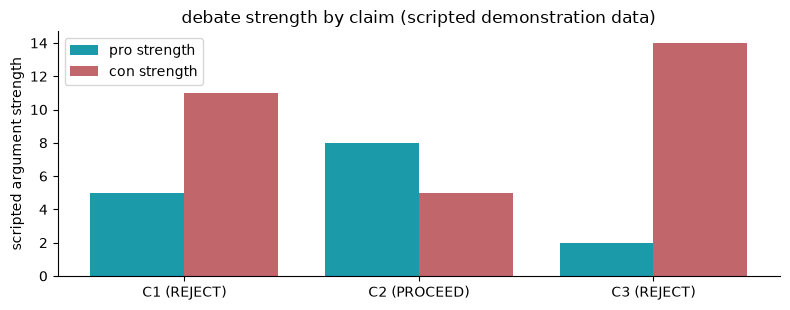

In [5]:
import io
import warnings
warnings.filterwarnings('ignore')  # keep library warnings out of stored outputs (QA-7)
import pandas as pd
import matplotlib.pyplot as plt

RECORDED_CSV = """claim,pro_strength,con_strength,verdict,disagreement
C1,5,11,REJECT,0.45
C2,8,5,PROCEED,0.62
C3,2,14,REJECT,0.14"""

csv_file = Path("runs/verdicts.csv")
if csv_file.exists():
    text = csv_file.read_text()
    print("chart data: this session's run (runs/verdicts.csv, written by the Run cell above)")
else:
    text = RECORDED_CSV
    print("chart data: the RECORDED run shipped in the repository (the Run cell has not been executed in this session)")
df = pd.read_csv(io.StringIO(text))
print(df.to_string(index=False))

CHART_MODE = "debate"
if CHART_MODE == "attempts":
    colors = ["#C1666B" if o == "ERROR" else ("#C9A227" if o == "EMPTY" else "#1B9AAA") for o in df["outcome"]]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    bars = ax.bar(df["attempt"], [1] * len(df), color=colors)
    for rect, outcome in zip(bars, df["outcome"]):
        ax.text(rect.get_x() + rect.get_width() / 2, 0.5, outcome, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.set_yticks([]); ax.set_xlabel("attempt"); ax.set_ylabel("outcome")
    ax.set_title("attempts by outcome (scripted demonstration data; teal SUCCESS, red ERROR, gold EMPTY)")
elif CHART_MODE == "routing":
    x = range(len(df))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar([i - 0.2 for i in x], df["agent_turns"], width=0.4, color="#1B9AAA", label="agent turns")
    ax.bar([i + 0.2 for i in x], df["total_calls"], width=0.4, color="#C9A227", label="total calls")
    ax.set_xticks(list(x)); ax.set_xticklabels(df["mode"]); ax.set_ylabel("count"); ax.legend()
    ax.set_title("turns and total calls by routing mode (scripted demonstration data)")
else:  # debate
    x = range(len(df))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar([i - 0.2 for i in x], df["pro_strength"], width=0.4, color="#1B9AAA", label="pro strength")
    ax.bar([i + 0.2 for i in x], df["con_strength"], width=0.4, color="#C1666B", label="con strength")
    ax.set_xticks(list(x)); ax.set_xticklabels(df["claim"] + " (" + df["verdict"] + ")")
    ax.set_ylabel("scripted argument strength"); ax.legend()
    ax.set_title("debate strength by claim (scripted demonstration data)")
for _a in [ax]:
    _a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 8 · Recorded run evidence

What the reference run produced in the repository, labelled by provenance: **ILLUSTRATIVE** for scripted demonstrations (outcomes fixed in the script — the pattern is the lesson) and **MEASURED** only for outcomes nobody typed in. Your live run above should reproduce the recorded figures exactly — if it does not, that disagreement is itself the lesson: find it before you believe either.

Label: **ILLUSTRATIVE** — scripted demonstration: from `runs/run-01.txt` (executed 2026-10-26, deterministic stubs, synthetic contract positions); argument strengths are scripted for the worked example, so the verdicts illustrate the pattern — against live advocates this is where measured verdict data would land.

- C1 (auto-renewal at +8%, no review window): pro 5 vs con 11 → REJECT, disagreement 0.45.
- C2 (24-hour incident-notice duty): pro 8 vs con 5 → PROCEED, disagreement 0.62 — the closest fight in the set; the strongest losing argument (define 'discovery' precisely) is the one to file.
- C3 (uncapped liability): pro 2 vs con 14 → REJECT, disagreement 0.14.
- Termination: DEBATE COMPLETE → TERMINATION: SIGNAL.
- Input: `data/claims.csv` — the positions the run reads. Results: `runs/verdicts.csv`, written by the run itself (ILLUSTRATIVE). Chart: drawn in the notebook from the run's own results table (ILLUSTRATIVE).

## 9 · Exercises

1. Add a fourth position of your own with pro/con arguments and strengths. Predict the verdict from the judge's rule before you run it — then check.
2. Weaken the judge: change the REJECT margin from 4 to 8. Which verdicts flip, and which real-world risk did you just silently accept?
3. C2 was the closest fight (disagreement 0.62). Write the one-paragraph note you would file for counsel from its strongest losing argument.

## 10 · Recap

One model polishes; two advocates expose. The debate pattern turns confidence theatre into an on-the-record balance of the strongest points each way — a prompt for human judgement that is worth more than the verdict it produces, and evidence of nothing by itself.

---
*Next in the series: see the repository index. Questions and corrections are welcome via the repo's Issues — this is a learning artefact, and it improves in public.*